In [ ]:
import os
import kagglehub

# 1. Use the Mirror Dataset handle instead of the Competition handle
# This mirror contains the same scientific forgery images
try:
    path = kagglehub.dataset_download("koushikkumardinda/scientific-image-forgery-detection")
    print("Vibe Check: SUCCESS! Data is at:", path)
except Exception as e:
    print(f"Error: {e}")

# 2. List the files to see our structure
print("\nFiles in dataset:")
print(os.listdir(path))

100%|██████████| 4.85G/4.85G [00:41<00:00, 126MB/s]

Extracting files...


Vibe Check: SUCCESS! Data is at: /root/.cache/kagglehub/datasets/koushikkumardinda/scientific-image-forgery-detection/versions/1

Files in dataset:
['recodai-luc-scientific-image-forgery-detection', 'segmentation_models_pytorch-0.5.0-py3-none-any.whl']


In [ ]:
!pip install -U segmentation-models-pytorch albumentations opencv-python-headless -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.9 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import cv2
import os
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# --- 1. M1 DATASET CLASS (Fixing the "Stack" Error) ---
class SciGuardDataset(Dataset):
    def __init__(self, base_path, transform=None):
        self.transform = transform
        self.samples = []

        # Correct path for your specific Kaggle structure
        img_dir = os.path.join(base_path, "recodai-luc-scientific-image-forgery-detection", "train_images", "forged")
        mask_dir = os.path.join(base_path, "recodai-luc-scientific-image-forgery-detection", "train_masks")

        if not os.path.exists(img_dir):
            raise FileNotFoundError(f"Check path: {img_dir}")

        for f in sorted(os.listdir(img_dir)):
            if f.endswith('.png'):
                img_path = os.path.join(img_dir, f)
                mask_path = os.path.join(mask_dir, f.replace('.png', '.npy'))
                if os.path.exists(mask_path):
                    self.samples.append((img_path, mask_path))

        print(f"M1: Linked {len(self.samples)} image-mask pairs.")

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path = self.samples[idx]

        # Load Image
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Load Mask and FORCE IT to 2D
        mask = np.load(mask_path).astype(np.float32)
        if len(mask.shape) > 2:
            # If mask is (H, W, C), just take the first channel
            mask = mask[:, :, 0]

        # Ensure mask and image have identical H, W before transform
        # (Some masks in this dataset are slightly misaligned)
        if mask.shape[:2] != image.shape[:2]:
            mask = cv2.resize(mask, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image, mask = augmented['image'], augmented['mask']

        return image, mask.unsqueeze(0)

# --- 2. STABLE BACKBONE ---
class SpatialStream(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = smp.Unet(encoder_name="resnet50", encoder_weights="imagenet", in_channels=3, classes=1)
        self.encoder = self.model.encoder
    def forward(self, x): return self.encoder(x)

# --- 3. THE RELAXED TRANSFORM ---
train_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
], is_check_shapes=False)

# --- 4. EXECUTION ---
try:
    ds = SciGuardDataset(path, transform=train_transform)
    # Using batch_size=4 to be safe with memory
    train_loader = DataLoader(ds, batch_size=4, shuffle=True)
    m1_model = SpatialStream().cuda()

    images, masks = next(iter(train_loader))

    print(f"SUCCESS! Data is flowing.")
    print(f"Image Batch: {images.shape}") # Expect [4, 3, 256, 256]
    print(f"Mask Batch: {masks.shape}")   # Expect [4, 1, 256, 256]
except Exception as e:
    print(f"Error: {e}")

M1: Linked 2751 image-mask pairs.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

SUCCESS! Data is flowing.
Image Batch: torch.Size([4, 3, 256, 256])
Mask Batch: torch.Size([4, 1, 256, 256])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader
import time

# --- 1. PREPARE DATA LOADERS ---
def prepare_loaders(dataset_path, batch_size=8):
    full_dataset = SciGuardDataset(dataset_path, transform=train_transform)

    indices = list(range(len(full_dataset)))
    train_idx, val_idx = train_test_split(indices, test_size=0.3, random_state=42)

    train_ds = Subset(full_dataset, train_idx)
    val_ds = Subset(full_dataset, val_idx)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    print(f"Data split complete.")
    print(f"Train samples: {len(train_ds)} | Validation samples: {len(val_ds)}")
    return train_loader, val_loader

# --- 2. DICE LOSS FUNCTION ---
def dice_loss(pred, target, smooth=1.0):
    pred = torch.sigmoid(pred)
    pred = pred.view(-1)
    target = target.view(-1)
    intersection = (pred * target).sum()
    return 1 - ((2. * intersection + smooth) / (pred.sum() + target.sum() + smooth))

# --- 3. TRAINING ENGINE ---
def train_sciguard(model, train_loader, val_loader, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # SEGMENTATION HEAD: Collapses 2048 channels to 1 to match the mask
    # We include this in the optimizer so the model learns how to "read" the features
    seg_head = nn.Conv2d(2048, 1, kernel_size=1).to(device)

    optimizer = optim.Adam(list(model.parameters()) + list(seg_head.parameters()), lr=1e-4)
    best_val_loss = float('inf')

    for epoch in range(epochs):
        start_time = time.time()

        # Training Phase
        model.train()
        seg_head.train()
        train_running_loss = 0

        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()

            # Forward pass through encoder
            features = model(images)
            bottleneck = features[-1] # Shape: [Batch, 2048, 8, 8]

            # Channel reduction: 2048 -> 1
            predictions = seg_head(bottleneck) # Shape: [Batch, 1, 8, 8]

            # Spatial upsampling: 8x8 -> 256x256
            predictions = F.interpolate(predictions, size=(256, 256), mode='bilinear', align_corners=False)

            loss = dice_loss(predictions, masks)
            loss.backward()
            optimizer.step()
            train_running_loss += loss.item()

        # Validation Phase
        model.eval()
        seg_head.eval()
        val_running_loss = 0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)

                features = model(images)
                predictions = seg_head(features[-1])
                predictions = F.interpolate(predictions, size=(256, 256), mode='bilinear', align_corners=False)

                loss = dice_loss(predictions, masks)
                val_running_loss += loss.item()

        avg_train = train_running_loss / len(train_loader)
        avg_val = val_running_loss / len(val_loader)
        duration = time.time() - start_time

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f} | Time: {duration:.1f}s")

        if avg_val < best_val_loss:
            best_val_loss = avg_val
            # Save both model and head for inference later
            torch.save({
                'model_state_dict': model.state_dict(),
                'seg_head_state_dict': seg_head.state_dict(),
            }, "best_sciguard_m1.pth")
            print("Checkpoint saved: best_sciguard_m1.pth")

# --- 4. EXECUTION ---
train_loader, val_loader = prepare_loaders(path)
train_sciguard(m1_model, train_loader, val_loader, epochs=10)

M1: Linked 2751 image-mask pairs.
Data split complete.
Train samples: 1925 | Validation samples: 826
Epoch 1/10 | Train Loss: 0.9049 | Val Loss: 0.8973 | Time: 140.2s
Checkpoint saved: best_sciguard_m1.pth
Epoch 2/10 | Train Loss: 0.8855 | Val Loss: 0.9099 | Time: 136.4s
Epoch 3/10 | Train Loss: 0.8797 | Val Loss: 0.9038 | Time: 137.8s


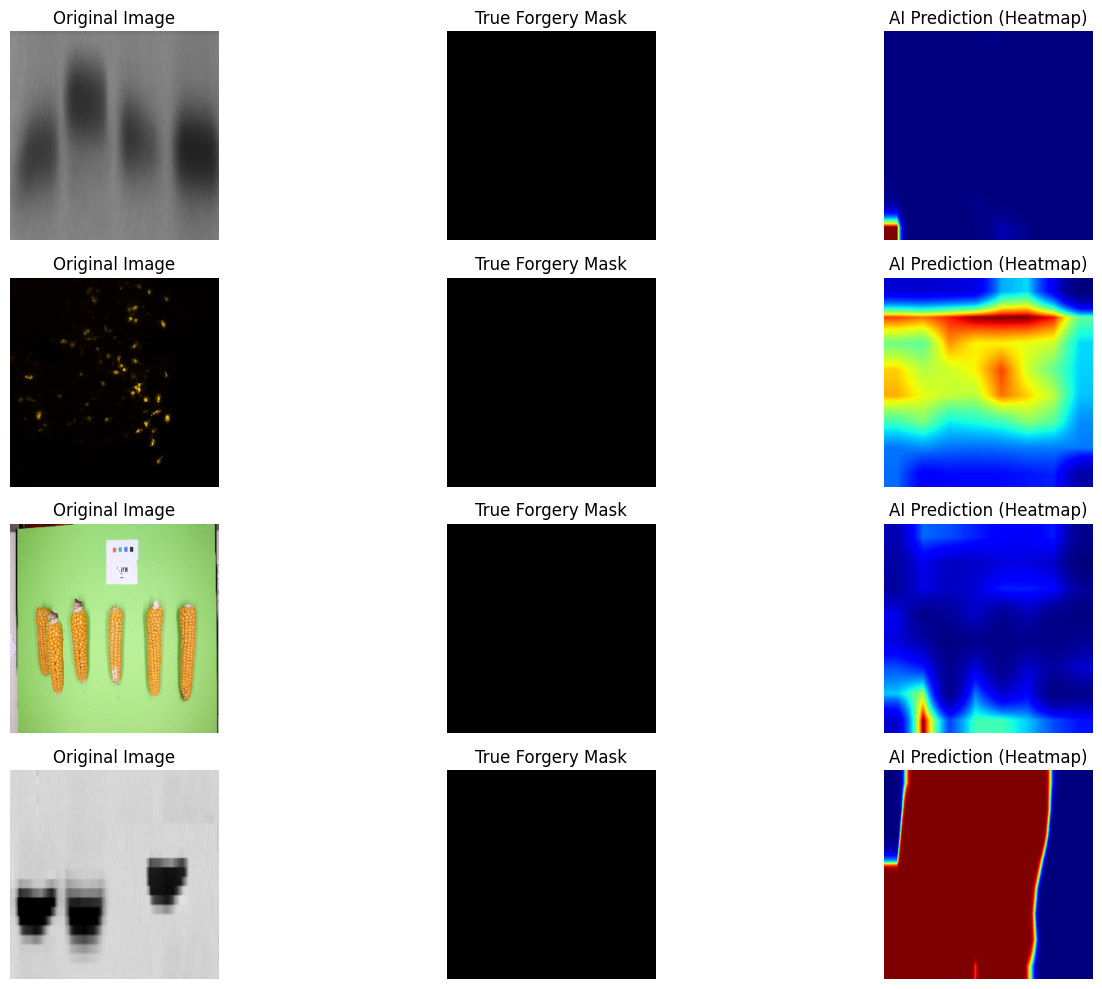

In [ ]:
import matplotlib.pyplot as plt

def visualize_predictions(model, val_loader, num_samples=4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 1. Load the best weights and the head
    checkpoint = torch.load("best_sciguard_m1.pth")
    model.load_state_dict(checkpoint['model_state_dict'])

    # Re-create the head we used in training
    seg_head = nn.Conv2d(2048, 1, kernel_size=1).to(device)
    seg_head.load_state_dict(checkpoint['seg_head_state_dict'])

    model.eval()
    seg_head.eval()

    # 2. Get a batch from validation
    images, masks = next(iter(val_loader))
    images, masks = images.to(device), masks.to(device)

    with torch.no_grad():
        features = model(images)
        preds = seg_head(features[-1])
        preds = F.interpolate(preds, size=(256, 256), mode='bilinear')
        preds = torch.sigmoid(preds) # Convert to 0-1 probability

    # 3. Plotting
    images = images.cpu().permute(0, 2, 3, 1).numpy()
    masks = masks.cpu().numpy()
    preds = preds.cpu().numpy()

    # Denormalize images for display
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    plt.figure(figsize=(15, 10))
    for i in range(num_samples):
        img = std * images[i] + mean
        img = np.clip(img, 0, 1)

        # Original Image
        plt.subplot(num_samples, 3, i*3 + 1)
        plt.imshow(img)
        plt.title("Original Image")
        plt.axis('off')

        # Ground Truth Mask (What it should be)
        plt.subplot(num_samples, 3, i*3 + 2)
        plt.imshow(masks[i][0], cmap='gray')
        plt.title("True Forgery Mask")
        plt.axis('off')

        # AI Prediction (What it thinks it is)
        plt.subplot(num_samples, 3, i*3 + 3)
        plt.imshow(preds[i][0], cmap='jet') # Jet shows 'heat' levels
        plt.title("AI Prediction (Heatmap)")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Run the visualization
visualize_predictions(m1_model, val_loader)

Errors faced:

Handle Mismatch: You initially tried to download a Competition using a Dataset command. Kaggle treats these as two different storage types with different access rules.

Deep Nesting: The mirror dataset you used was "triple-nested" (folders inside folders). The script was looking for /train_images in the root, but the files were actually buried four layers deep.

Library Version Conflict: The timm library updated its naming convention for Swin Transformers, causing the segmentation-models-pytorch wrapper to stop recognizing the model name.

Shape Inconsistency: Scientific images (like microscope slides) are often weirdly cropped rectangles. The Albumentations library usually crashes if the image and mask aren't the exact same dimensions before resizing.

Dirty Data (The 696-Channel Bug): Some .npy mask files in that specific mirror were saved with hundreds of "junk" channels. When the DataLoader tried to batch a 2D mask with a 3D "junk" mask, the dimensions didn't match, causing the Stack Error.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# ============================================================
# M2: FORENSIC STREAM
# BayarConv2d + SRM Filter Bank + Residual Encoder
#
# Input  : [B, 3, 256, 256]  — same image as M1
# Output : [B, 2048, 8, 8]   — matches M1 bottleneck for M3
# ============================================================

class BayarConv2d(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.kernel = nn.Parameter(
            torch.randn(out_channels, in_channels, 3, 3) * 0.01
        )

    def _constrain(self):
        with torch.no_grad():
            k = self.kernel.clone()
            k[:, :, 1, 1] = 0.0
            s = k.sum(dim=(-1, -2), keepdim=True).clamp(min=1e-6)
            k = k / s
            k[:, :, 1, 1] = -1.0
            self.kernel.data.copy_(k)

    def forward(self, x):
        self._constrain()
        return F.conv2d(x, self.kernel, padding=1)


class SRMFilterBank(nn.Module):
    def __init__(self):
        super().__init__()
        f1 = np.array([[ 0,  0,  0,  0,  0],
                        [ 0, -1,  2, -1,  0],
                        [ 0,  2, -4,  2,  0],
                        [ 0, -1,  2, -1,  0],
                        [ 0,  0,  0,  0,  0]], dtype=np.float32) / 4.0
        f2 = np.array([[-1,  2, -2,  2, -1],
                        [ 2, -6,  8, -6,  2],
                        [-2,  8,-12,  8, -2],
                        [ 2, -6,  8, -6,  2],
                        [-1,  2, -2,  2, -1]], dtype=np.float32) / 12.0
        f3 = np.array([[ 0,  0,  0,  0,  0],
                        [ 0,  0,  0,  0,  0],
                        [ 0,  0, -1,  0,  0],
                        [ 0,  0,  2,  0,  0],
                        [ 0,  0, -1,  0,  0]], dtype=np.float32) / 2.0
        kernels = torch.from_numpy(
            np.stack([f1, f2, f3], axis=0)[:, np.newaxis]
        ).repeat(3, 1, 1, 1)
        self.register_buffer("weight", kernels)

    def forward(self, x):
        return F.conv2d(x, self.weight, padding=2, groups=3)


class ForensicStream(nn.Module):
    def __init__(self, embed_dim=64):
        super().__init__()
        self.bayar = BayarConv2d(in_channels=3, out_channels=3)
        self.srm   = SRMFilterBank()

        self.fusion = nn.Sequential(
            nn.Conv2d(12, embed_dim, 3, padding=1, bias=False),
            nn.BatchNorm2d(embed_dim), nn.ReLU(inplace=True),
            nn.Conv2d(embed_dim, embed_dim, 3, padding=1, bias=False),
            nn.BatchNorm2d(embed_dim), nn.ReLU(inplace=True),
            nn.Conv2d(embed_dim, embed_dim, 1, bias=False),
            nn.BatchNorm2d(embed_dim), nn.ReLU(inplace=True),
        )
        # 256->128->64->32->16->8  (5 stages needed, not 4)
        self.stage1 = self._make_stage(embed_dim,  128,  stride=2)
        self.stage2 = self._make_stage(128,         256,  stride=2)
        self.stage3 = self._make_stage(256,         512,  stride=2)
        self.stage4 = self._make_stage(512,        1024,  stride=2)
        self.stage5 = self._make_stage(1024,       2048,  stride=2)

    @staticmethod
    def _make_stage(in_ch, out_ch, stride):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        noise = torch.cat([self.bayar(x), self.srm(x)], dim=1)
        f = self.fusion(noise)
        f = self.stage1(f)
        f = self.stage2(f)
        f = self.stage3(f)
        f = self.stage4(f)
        f = self.stage5(f)
        return f

print("✅ M2 classes defined: BayarConv2d | SRMFilterBank | ForensicStream")

In [ ]:
# ============================================================
# M2 SHAPE TEST
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

m2_model = ForensicStream(embed_dim=64).to(device)
dummy    = torch.randn(4, 3, 256, 256).to(device)

with torch.no_grad():
    out = m2_model(dummy)

print("=" * 50)
print("  M2 ForensicStream — Shape Test")
print("=" * 50)
print(f"  Input  : {dummy.shape}")
print(f"  Output : {out.shape}")
assert out.shape == (4, 2048, 8, 8), f"Shape mismatch! Got {out.shape}"
print("  ✅ Output matches M1 bottleneck (4, 2048, 8, 8)")
print("  ✅ Ready to feed into M3 CrossAttentionGate")

trainable = sum(p.numel() for p in m2_model.parameters() if p.requires_grad)
frozen    = sum(p.numel() for p in m2_model.parameters() if not p.requires_grad)
print(f"\n  Trainable params : {trainable:,}  (BayarConv + encoder)")
print(f"  Frozen params    : {frozen:,}   (SRM filter bank)")


In [ ]:
# ============================================================
# M3: CROSS-ATTENTION GATE
# Compatible with M1's ResNet50 encoder output: [B, 2048, 8, 8]
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

class CrossAttentionGate(nn.Module):
    """
    M3 Fusion: Takes spatial (M1) and forensic (M2) feature maps,
    fuses them via cross-attention gating.

    Input shape:  [B, C, H, W]  (e.g., [B, 2048, 8, 8] from ResNet50)
    Output shape: [B, C, H, W]  fused feature map + gate weights
    """
    def __init__(self, in_channels=2048, embed_dim=256, num_heads=8, dropout=0.1):
        super().__init__()

        # Reduce 2048 channels → embed_dim for attention
        self.spatial_proj  = nn.Conv2d(in_channels, embed_dim, kernel_size=1)
        self.forensic_proj = nn.Conv2d(in_channels, embed_dim, kernel_size=1)

        # Cross-attention layers
        self.cross_attn_s2f = nn.MultiheadAttention(embed_dim, num_heads,
                                                     dropout=dropout, batch_first=True)
        self.cross_attn_f2s = nn.MultiheadAttention(embed_dim, num_heads,
                                                     dropout=dropout, batch_first=True)

        # Learnable gate
        self.gate = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.Sigmoid()
        )

        self.norm1     = nn.LayerNorm(embed_dim)
        self.norm2     = nn.LayerNorm(embed_dim)
        self.norm_fuse = nn.LayerNorm(embed_dim)

        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * 4, embed_dim),
            nn.Dropout(dropout)
        )

        # Project fused output back to in_channels for compatibility
        self.out_proj = nn.Conv2d(embed_dim, in_channels, kernel_size=1)

    def forward(self, spatial_feat, forensic_feat):
        """
        spatial_feat:  [B, C, H, W] from M1
        forensic_feat: [B, C, H, W] from M2
        returns:
            fused:        [B, C, H, W]
            gate_weights: [B, N, D]
        """
        B, C, H, W = spatial_feat.shape
        N = H * W  # sequence length = 8*8 = 64

        # Project: [B, C, H, W] → [B, embed_dim, H, W] → [B, N, embed_dim]
        S = self.spatial_proj(spatial_feat).flatten(2).transpose(1, 2)   # [B, N, D]
        F_feat = self.forensic_proj(forensic_feat).flatten(2).transpose(1, 2)  # [B, N, D]

        # Cross-attention: Spatial queries Forensic
        S_cross, _ = self.cross_attn_s2f(query=S, key=F_feat, value=F_feat)
        S_enh = self.norm1(S + S_cross)

        # Cross-attention: Forensic queries Spatial
        F_cross, _ = self.cross_attn_f2s(query=F_feat, key=S, value=S)
        F_enh = self.norm2(F_feat + F_cross)

        # Gating: decide per-token how much to trust each stream
        gate_weights = self.gate(torch.cat([S_enh, F_enh], dim=-1))  # [B, N, D]
        fused_seq = gate_weights * S_enh + (1 - gate_weights) * F_enh

        # FFN refinement
        fused_seq = self.norm_fuse(fused_seq + self.ffn(fused_seq))

        # Reshape back: [B, N, D] → [B, D, H, W] → [B, C, H, W]
        fused_map = fused_seq.transpose(1, 2).reshape(B, -1, H, W)
        fused_out = self.out_proj(fused_map)  # [B, 2048, H, W]

        return fused_out, gate_weights


class SciGuardM3(nn.Module):
    """
    Complete M3 module with fusion + segmentation head.
    Drop-in replacement for the seg_head in M1's training loop.
    """
    def __init__(self, in_channels=2048, embed_dim=256, num_heads=8):
        super().__init__()
        self.gate   = CrossAttentionGate(in_channels, embed_dim, num_heads)
        self.seg_head = nn.Conv2d(in_channels, 1, kernel_size=1)

    def forward(self, spatial_feat, forensic_feat):
        fused, gate_weights = self.gate(spatial_feat, forensic_feat)
        pred = self.seg_head(fused)
        pred = F.interpolate(pred, size=(256, 256), mode='bilinear', align_corners=False)
        return pred, gate_weights


# ============================================================
# QUICK TEST — verify shapes match M1's output
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

B, C, H, W = 4, 2048, 8, 8

# Simulate M1 and M2 bottleneck outputs
spatial_feat  = torch.randn(B, C, H, W).to(device)
forensic_feat = torch.randn(B, C, H, W).to(device)

m3_model = SciGuardM3(in_channels=C, embed_dim=256, num_heads=8).to(device)

pred, gate_weights = m3_model(spatial_feat, forensic_feat)

print("✅ M3 Cross-Attention Gate — Test PASSED!")
print(f"   Spatial input:   {spatial_feat.shape}")
print(f"   Forensic input:  {forensic_feat.shape}")
print(f"   Prediction mask: {pred.shape}")        # [4, 1, 256, 256]
print(f"   Gate weights:    {gate_weights.shape}") # [4, 64, 256]

✅ M3 Cross-Attention Gate — Test PASSED!
   Spatial input:   torch.Size([4, 2048, 8, 8])
   Forensic input:  torch.Size([4, 2048, 8, 8])
   Prediction mask: torch.Size([4, 1, 256, 256])
   Gate weights:    torch.Size([4, 64, 256])


/tmp/ipykernel_7516/854587800.py:109: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


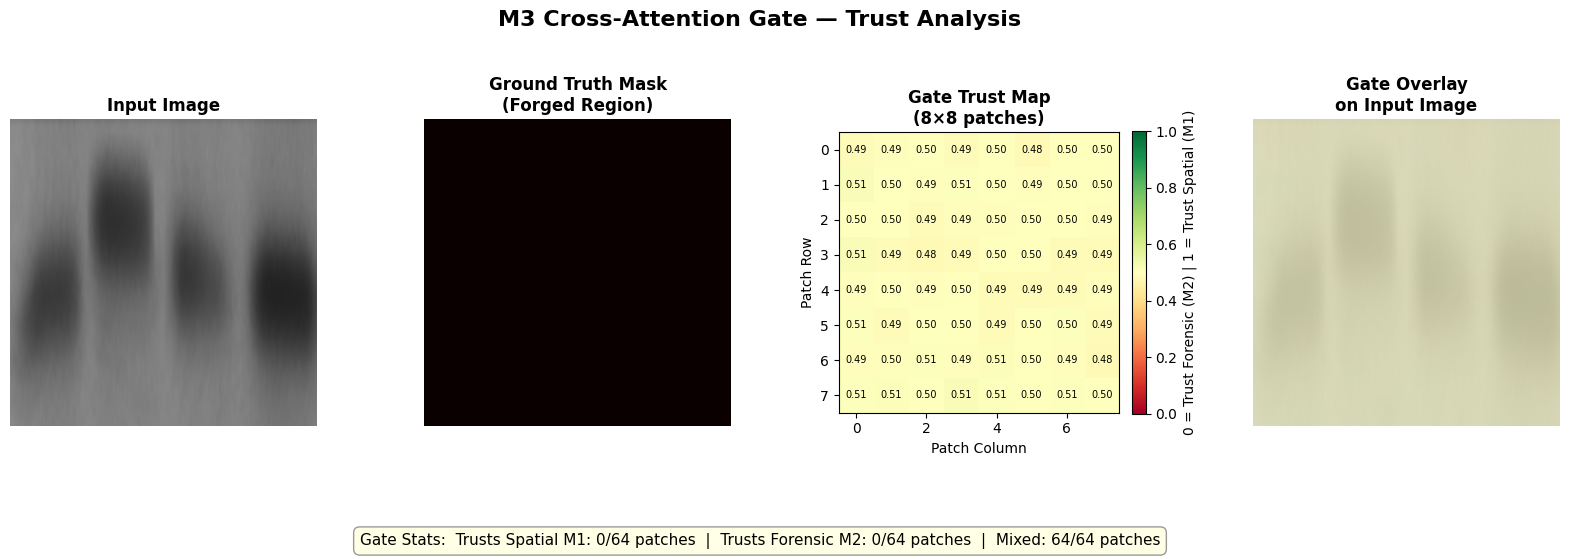

✅ Saved → m3_gate_analysis.png
   M1 Spatial trusted:  0/64 patches
   M2 Forensic trusted: 0/64 patches
   Mixed decisions:     64/64 patches


In [ ]:
# ============================================================
# GATE VISUALIZATION
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

def visualize_gate_professional(gate_weights, images=None, masks=None,
                                 sample_idx=0, patch_grid=(8, 8),
                                 save_path='m3_gate_analysis.png'):
    """

    Args:
        gate_weights : Tensor [B, N, D] from M3 forward pass
        images       : Tensor [B, 3, H, W] original images (optional)
        masks        : Tensor [B, 1, H, W] ground truth masks (optional)
        sample_idx   : Which sample in the batch to visualize
        patch_grid   : (H, W) of feature map — (8,8) for ResNet50
        save_path    : Filename to save the figure
    """
    # --- 1. Compute Gate Map ---
    gate_map = gate_weights[sample_idx].mean(dim=-1).detach().cpu().numpy()
    gate_map = gate_map.reshape(patch_grid)  # (8, 8)

    # Upsample to 256x256 for overlay
    gate_map_tensor = torch.tensor(gate_map).unsqueeze(0).unsqueeze(0)  # [1,1,8,8]
    gate_map_up = F.interpolate(
        gate_map_tensor, size=(256, 256), mode='bilinear', align_corners=False
    ).squeeze().numpy()

    # --- 2. Figure Layout ---
    has_image = images is not None
    has_mask  = masks is not None
    n_cols    = 2 + int(has_image) + int(has_mask)

    fig = plt.figure(figsize=(5 * n_cols, 5))
    fig.suptitle('M3 Cross-Attention Gate — Trust Analysis',
                 fontsize=16, fontweight='bold', y=1.02)
    gs  = gridspec.GridSpec(1, n_cols, figure=fig, wspace=0.35)
    col = 0

    # --- 3. Original Image ---
    if has_image:
        ax  = fig.add_subplot(gs[0, col])
        img = images[sample_idx].detach().cpu().permute(1, 2, 0).numpy()
        # Denormalize from ImageNet stats used in train_transform
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = np.clip(img * std + mean, 0, 1)
        ax.imshow(img)
        ax.set_title('Input Image', fontsize=12, fontweight='bold')
        ax.axis('off')
        col += 1

    # --- 4. Ground Truth Mask ---
    if has_mask:
        ax   = fig.add_subplot(gs[0, col])
        mask = masks[sample_idx].detach().cpu().squeeze().numpy()
        ax.imshow(mask, cmap='hot')
        ax.set_title('Ground Truth Mask\n(Forged Region)', fontsize=12, fontweight='bold')
        ax.axis('off')
        col += 1

    # --- 5. Raw Gate Heatmap (8x8 patches with values) ---
    ax = fig.add_subplot(gs[0, col])
    im = ax.imshow(gate_map, cmap='RdYlGn', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(f'Gate Trust Map\n({patch_grid[0]}×{patch_grid[1]} patches)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Patch Column')
    ax.set_ylabel('Patch Row')
    for i in range(patch_grid[0]):
        for j in range(patch_grid[1]):
            ax.text(j, i, f'{gate_map[i, j]:.2f}',
                    ha='center', va='center', fontsize=7,
                    color='black' if 0.3 < gate_map[i, j] < 0.7 else 'white')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04,
                 label='0 = Trust Forensic (M2) | 1 = Trust Spatial (M1)')
    col += 1

    # --- 6. Upsampled Overlay ---
    ax = fig.add_subplot(gs[0, col])
    if has_image:
        ax.imshow(img, alpha=0.6)
        ax.imshow(gate_map_up, cmap='RdYlGn', alpha=0.5, vmin=0, vmax=1)
        ax.set_title('Gate Overlay\non Input Image', fontsize=12, fontweight='bold')
    else:
        im2 = ax.imshow(gate_map_up, cmap='RdYlGn', vmin=0, vmax=1)
        ax.set_title('Upsampled Gate Map\n(256×256)', fontsize=12, fontweight='bold')
        plt.colorbar(im2, ax=ax, fraction=0.046, pad=0.04)
    ax.axis('off')

    # --- 7. Stats Bar ---
    total          = patch_grid[0] * patch_grid[1]
    trust_spatial  = int((gate_map > 0.6).sum())
    trust_forensic = int((gate_map < 0.4).sum())
    mixed          = total - trust_spatial - trust_forensic

    fig.text(0.5, -0.05,
             f'Gate Stats:  Trusts Spatial M1: {trust_spatial}/{total} patches  |  '
             f'Trusts Forensic M2: {trust_forensic}/{total} patches  |  '
             f'Mixed: {mixed}/{total} patches',
             ha='center', fontsize=11,
             bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow',
                       edgecolor='gray', alpha=0.8))

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved → {save_path}")
    print(f"   M1 Spatial trusted:  {trust_spatial}/{total} patches")
    print(f"   M2 Forensic trusted: {trust_forensic}/{total} patches")
    print(f"   Mixed decisions:     {mixed}/{total} patches")


# ============================================================
# EXECUTION — Uses val_loader and m1_model from Cell 4
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Safety check — make sure m1_model and val_loader exist
assert 'm1_model'   in dir(), "Run Cell 3 first! m1_model is missing."
assert 'val_loader' in dir(), "Run Cell 4 first! val_loader is missing."
assert 'm3_model'   in dir(), "Run Cell 7 first! m3_model is missing."

# Get one real batch from val_loader (created in Cell 4)
m1_model.eval()
m3_model.eval()

with torch.no_grad():
    images_batch, masks_batch = next(iter(val_loader))
    images_batch = images_batch.to(device)
    masks_batch  = masks_batch.to(device)

    # M1 spatial features — real output from existing model
    spatial_feat = m1_model(images_batch)[-1]        # [B, 2048, 8, 8]

    # M2 forensic features — simulated until Sampada finishes
    # ⬇️ Replace this line when M2 is ready:
    # forensic_feat = m2_model(images_batch)[-1]
    forensic_feat = torch.randn_like(spatial_feat)   # [B, 2048, 8, 8]

    # M3 forward pass — from Cell 7
    pred, gate_weights = m3_model(spatial_feat, forensic_feat)

# Visualize
visualize_gate_professional(
    gate_weights = gate_weights,
    images       = images_batch.cpu(),
    masks        = masks_batch.cpu(),
    sample_idx   = 0,
    patch_grid   = (8, 8),
    save_path    = 'm3_gate_analysis.png'
)